# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# importar librerías

In [2]:
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("Cantidad de valores nulos")
print(users.isna().sum())
print("Proporción de valores nulos")
print(users.isna().mean())

Cantidad de valores nulos
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de valores nulos
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("Cantidad de valores nulos")
print(usage.isna().sum())
print("Proporción de valores nulos")
print(usage.isna().mean())

Cantidad de valores nulos
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


**Comentario**:

**Diagnóstico:**
Se identificaron valores faltantes en ambos datasets:

**users:**
- `city`: 469 nulos (11.7%) — rango entre 5% y 30%, se investiga para imputar.
  Además contiene 96 registros con sentinel "?" que representan ciudad desconocida.
  En total, 565 registros sin ciudad válida.
- `churn_date`: 3534 nulos (88.4%) — esperado y correcto: representa clientes activos 
  sin fecha de baja. No es un error, es información válida (NaN = cliente activo).

**usage:**
- `date`: 50 nulos (0.12%) — menor al 5%, caso MCAR simple.
- `duration`: 22076 nulos (55.2%) — esperado: los registros de tipo "text" no tienen 
  duración. Es MAR dependiendo de la columna `type`, no es un error.
- `length`: 17896 nulos (44.7%) — mismo caso: los registros de tipo "call" no tienen 
  longitud de mensaje. MAR por diseño del dataset.

**Valores nulos**

**¿Qué columnas tienen valores faltantes y en qué proporción?**
- `city` (users): 11.7% — proporción moderada que requiere tratamiento.
- `churn_date` (users): 88.4% — esperado, representa clientes activos.
- `date` (usage): 0.12% — proporción muy baja.
- `duration` (usage): 55.2% — MAR por diseño (solo aplica a llamadas).
- `length` (usage): 44.7% — MAR por diseño (solo aplica a mensajes).

**Indica qué harías: ¿imputar, eliminar, ignorar?**
- `city`: imputar con "unknown" (junto con los sentinel "?"). Al ser 11.7% no conviene eliminar.
- `churn_date`: ignorar — NaN significa cliente activo, es información válida.
- `date`: eliminar las 50 filas — sin fecha no son analizables temporalmente (MCAR, <5%).
- `duration` y `length`: ignorar — los nulos son MAR por diseño según el tipo de evento. 
  Se analizarán por separado filtrando por `type`.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna user_id tiene IDs entre 10000 y 13999, sin valores imposibles. Es un identificador único, no requiere limpieza.
- La columna age tiene un mínimo de -999, que es un sentinel clásico. La std de 123 confirma que distorsiona la distribución. Acción: reemplazar -999 con pd.NA en la limpieza.

In [13]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas id y user_id son IDs secuenciales sin valores imposibles. No requieren limpieza.
- Las columnas duration y length tienen mínimo 0.0 — hay llamadas y mensajes de duración/longitud cero, posible sentinel o error. Acción: revisar y eliminar registros con duration <= 0 o length <= 0 en la limpieza. Los máximos (120 min, 1490 chars) son altos pero posibles; se evaluarán como outliers más adelante.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(col)
    print(users[col].value_counts())
    print()

city
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna city tiene 7 valores únicos: 6 ciudades válidas (Bogotá, CDMX, Medellín, GDL, Cali, MTY) 
  y el sentinel "?" con 96 registros. Acción: reemplazar "?" con "unknown".
- La columna plan tiene solo 2 valores (Basico y Premium), sin problemas. 
  Distribución 65% Basico / 35% Premium.

In [16]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna type tiene solo 2 valores válidos: "text" (22092) y "call" (17908). 
  Sin sentinels ni valores inválidos. Distribución levemente mayor hacia mensajes de texto.

**Comentario**:

**Diagnóstico:**
Se identificaron valores inválidos y sentinels en los siguientes campos:

- `age` (users): contiene el sentinel -999, un valor imposible para una edad real. 
  La std de 123 confirma que distorsiona gravemente la distribución. Es un caso de 
  valor inválido que debe tratarse antes de cualquier análisis demográfico.

- `city` (users): contiene 96 registros con "?" como sentinel de ciudad desconocida, 
  además de 469 NaN reales. Ambos representan ausencia de información geográfica.

- `duration` y `length` (usage): mínimo de 0.0 en ambas columnas. Las llamadas de 
  duración cero y mensajes de longitud cero no representan uso real del servicio.

**¿En qué columnas encontraste valores inválidos o sentinels?**
- `age`: sentinel -999 (edad imposible)
- `city`: sentinel "?" (ciudad desconocida)
- `duration`: valores 0.0 (llamadas sin duración real)
- `length`: valores 0.0 (mensajes sin contenido real)

**¿Qué acción tomarías?**
- `age`: reemplazar -999 con pd.NA antes de analizar. Acción: REPLACE → pd.NA
- `city`: reemplazar "?" con "unknown" y unificar con los NaN existentes. Acción: REPLACE → "unknown"
- `duration` y `length`: eliminar registros con valor 0 ya que no representan 
  uso real del servicio. Acción: DROP registros con duration <= 0 o length <= 0
- `duration` max 120 min y `length` max 1490 chars son altos pero posibles; 
  se conservan y evaluarán como outliers en pasos posteriores.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [19]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En reg_date aparecen registros en 2022, 2023 y 2024 (válidos) y 40 registros con año 2026, 
que es un año futuro al momento de captura de los datos. Son errores de registro.

In [20]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()


2024.0    39950
Name: date, dtype: int64

En date todos los 39950 registros con fecha están en 2024, dentro del rango esperado. 
Los 50 NaN son fechas mal formateadas. Sin años fuera de rango.

**Comentario**:

**Diagnóstico:**
Se identificaron problemas de calidad en las columnas de fecha de ambos datasets:

- `reg_date` (users): columna convertida exitosamente a datetime. Contiene registros en 2022, 
  2023 y 2024 (válidos, dentro del periodo de análisis) y 40 registros con año 2026, 
  que es un año futuro al momento de captura de los datos. Estos representan errores de 
  captura que distorsionarían cualquier análisis temporal si no se tratan.

- `date` (usage): columna convertida exitosamente a datetime. El 100% de los registros con 
  fecha válida están en 2024, dentro del rango esperado. Los 50 NaN (0.12%) se generaron 
  porque las fechas originales estaban mal formateadas y `errors='coerce'` las convirtió a NaT.
  Son un caso MCAR (faltante completamente al azar) con proporción menor al 5%.

**Fechas fuera de rango**

**¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)**
Sí. En `reg_date` aparecen 40 registros (1% del total) con año 2026, un año que no había 
transcurrido al momento de guardar los datos (2024). Estos son errores de captura claros 
que no representan clientes reales dentro del periodo analizado.
En `date` de usage no aparecen años imposibles — todos los registros con fecha válida 
corresponden a 2024.

**¿Qué harías con ellas?**
- `reg_date` año 2026: acción DROP. Se eliminarán los 40 registros en la limpieza 
  filtrando `year <= 2024`, ya que son errores imposibles que no aportan información real 
  y su presencia distorsionaría análisis temporales de registro de clientes.
- `date` NaN en usage: acción DROP. Se eliminarán las 50 filas con `date` nula, 
  ya que sin fecha no es posible ubicarlos temporalmente ni incluirlos en análisis 
  de comportamiento mensual. Al ser MCAR y representar solo el 0.12%, su eliminación 
  no introduce sesgo significativo.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [23]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].where(users['reg_date'].dt.year <= 2024, pd.NaT)

# Verificar cambios
users['reg_date'].dt.year.value_counts().sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [25]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

**Diagnóstico de nulos en `duration` y `length`:**

Los resultados confirman que los nulos son MAR (Missing At Random) dependiendo de la columna `type`:

- `duration`: los 22076 nulos están concentrados exclusivamente en registros de tipo "text". 
  Las llamadas ("call") no tienen ningún nulo en duration. Esto significa que la ausencia 
  de duración depende completamente del tipo de evento — un mensaje de texto no tiene 
  duración de llamada, por diseño.

- `length`: los 17896 nulos están concentrados exclusivamente en registros de tipo "call". 
  Los mensajes de texto ("text") no tienen ningún nulo en length. Mismo caso — una llamada 
  no tiene longitud de mensaje, por diseño.

**Decisión:** se dejan como nulos y se conservan. No representan errores de captura sino 
la naturaleza del dato: cada tipo de evento solo tiene sentido en su propia métrica. 
El análisis de llamadas usará `duration` filtrando por `type == "call"`, y el análisis 
de mensajes usará `length` filtrando por `type == "text"`.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
# Ya quedaron renombradas en el agg anterior con los nombres correctos

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [30]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

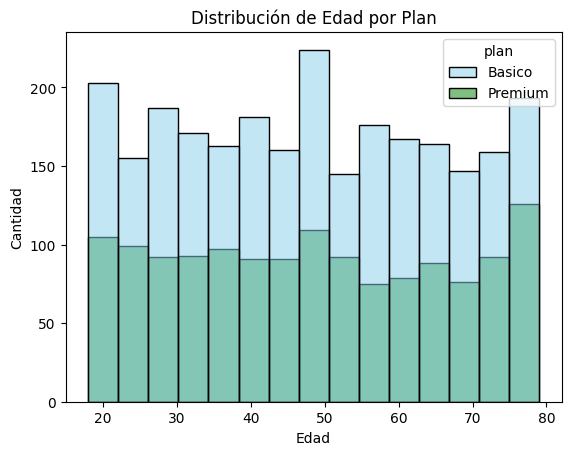

In [31]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', bins=15, palette=['skyblue','green'])
plt.title('Distribución de Edad por Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.show()

- Distribución aproximadamente uniforme entre 20 y 80 años, con un leve pico alrededor de los 50 años.
- Ambos planes (Basico y Premium) se distribuyen de manera similar a lo largo de todos los rangos de edad, sin una concentración clara en ningún grupo etario.
- La proporción Premium/Basico se mantiene relativamente constante en todos los rangos de edad, lo que indica que la adopción del plan Premium no está fuertemente asociada a la edad del cliente.
- Tipo de distribución: aproximadamente uniforme, sin sesgo marcado a la derecha ni a la izquierda.

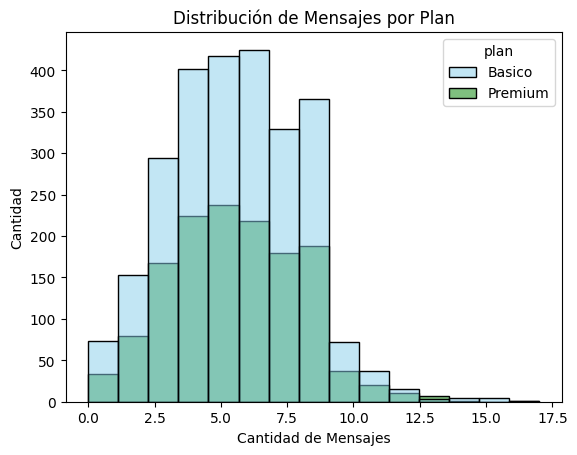

In [32]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=15, palette=['skyblue','green'])
plt.title('Distribución de Mensajes por Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad')
plt.show()

- Distribución sesgada a la derecha (right-skewed): la mayoría de los usuarios envía entre 3 y 8 mensajes, con pocos usuarios enviando más de 12.
- El pico de la distribución está entre 5 y 8 mensajes, lo que representa el comportamiento típico del cliente.
- Los usuarios Premium muestran una proporción ligeramente mayor en los rangos de mensajes más altos (8-10), sugiriendo que los clientes Premium tienden a usar más el servicio de mensajería.
- La cola derecha indica la presencia de usuarios con uso muy alto (hasta 17 mensajes) que podrían ser candidatos a análisis de outliers.
- Tipo de distribución: sesgada a la derecha. La mediana representa mejor al usuario típico que la media.

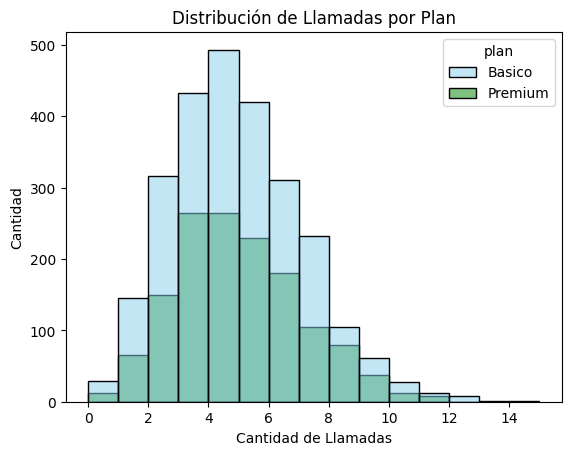

In [33]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=15, palette=['skyblue','green'])
plt.title('Distribución de Llamadas por Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad')
plt.show()

- Distribución sesgada a la derecha (right-skewed): la mayoría de los usuarios realiza entre 3 y 7 llamadas, con pocos usuarios superando las 10.
- El pico de la distribución está entre 4 y 5 llamadas, representando el comportamiento típico del cliente.
- Los usuarios Premium muestran una proporción más alta en los rangos de mayor cantidad de llamadas (6-8), sugiriendo que los clientes Premium hacen un uso más intensivo del servicio de voz.
- La cola derecha llega hasta 15 llamadas, con muy pocos usuarios en ese rango — posibles candidatos a outliers o usuarios de alto consumo.
- Tipo de distribución: sesgada a la derecha. La mediana es más representativa del usuario típico que la media.

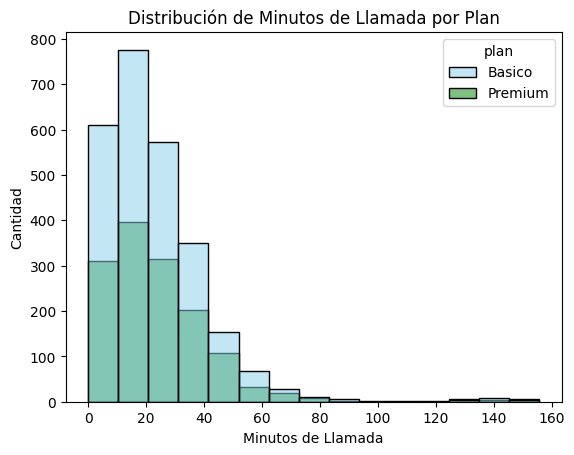

In [35]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=15, palette=['skyblue','green'])
plt.title('Distribución de Minutos de Llamada por Plan')
plt.xlabel('Minutos de Llamada')
plt.ylabel('Cantidad')
plt.show()

- Distribución fuertemente sesgada a la derecha (right-skewed): la gran mayoría de usuarios acumula entre 0 y 40 minutos de llamada, con una cola larga que llega hasta 155 minutos.
- El pico más alto está en el rango 0-10 minutos, indicando que el usuario típico de ConnectaTel hace un uso moderado o bajo del servicio de voz.
- Los usuarios Premium representan una proporción significativa en los rangos medios (10-40 minutos), lo que sugiere que los clientes Premium hacen un uso más consistente del servicio de voz.
- La cola derecha (más de 80 minutos) contiene muy pocos usuarios — posibles outliers o clientes de alto valor que consumen mucho más que el promedio.
- Tipo de distribución: fuertemente sesgada a la derecha. La mediana (≈19.78 min) representa mucho mejor al usuario típico que la media (≈23.3 min), que está inflada por los valores extremos de la cola.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

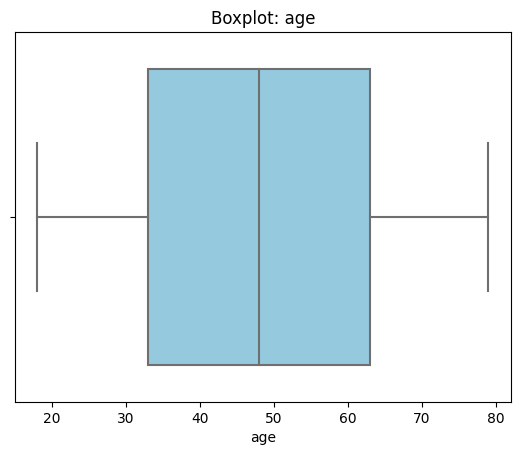

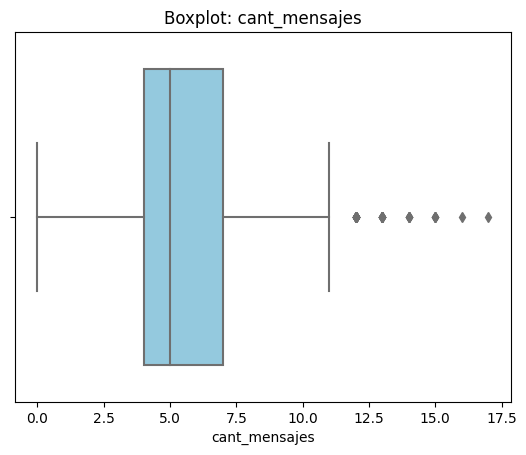

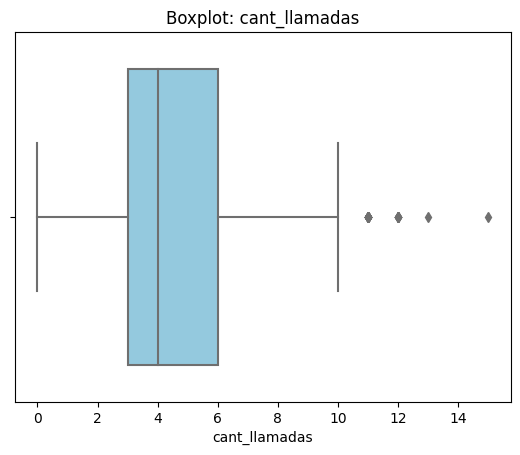

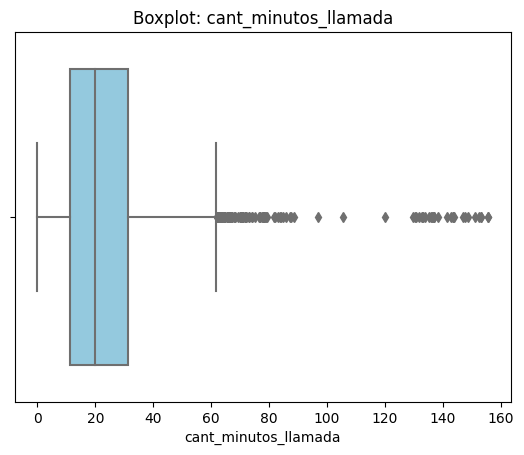

In [36]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()

- Age: no presenta outliers. La caja es amplia (IQR de ~30 años), los bigotes llegan hasta 18 y 80, y no hay puntos fuera de ellos. Distribución uniforme sin valores extremos.
- cant_mensajes: presenta outliers en el extremo superior. Se observan puntos entre 12 y 17 mensajes, fuera del bigote derecho. Son pocos usuarios con consumo inusualmente alto de mensajería.
- cant_llamadas: presenta outliers en el extremo superior. Se observan puntos entre 11 y 15 llamadas, fuera del bigote derecho. Usuarios con uso de voz significativamente mayor al típico.
- cant_minutos_llamada: presenta la mayor cantidad de outliers, concentrados entre 60 y 155 minutos. La caja es estrecha (la mayoría entre 0 y 40 minutos) y la cola derecha es muy larga, indicando un grupo reducido de usuarios con consumo de voz extremadamente alto.

In [37]:
# Calcular limites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"{col} → Q1: {Q1}, Q3: {Q3}, IQR: {IQR}, Límite superior: {limite_superior}")

cant_mensajes → Q1: 4.0, Q3: 7.0, IQR: 3.0, Límite superior: 11.5
cant_llamadas → Q1: 3.0, Q3: 6.0, IQR: 3.0, Límite superior: 10.5
cant_minutos_llamada → Q1: 11.12, Q3: 31.415, IQR: 20.295, Límite superior: 61.8575


In [38]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


- cant_mensajes: MANTENER outliers. Límite superior IQR = 11.5, max = 17. 
  Los valores entre 12 y 17 superan el límite pero representan usuarios reales 
  con alto consumo de mensajería. En telecomunicaciones, un usuario que envía 
  más mensajes que el promedio es un cliente de alto valor, no un error de captura.
  Acción: conservar y analizar como segmento de uso alto.

- cant_llamadas: MANTENER outliers. Límite superior IQR = 10.5, max = 15. 
  Los valores entre 11 y 15 superan el límite pero son comportamientos reales 
  de usuarios con uso intensivo del servicio de voz. No hay razón de negocio 
  para eliminarlos — pueden representar clientes corporativos o de alto valor.
  Acción: conservar y analizar como segmento de uso alto.

- cant_minutos_llamada: MANTENER outliers. Límite superior IQR = 61.9, max = 155.69. 
  Aunque la diferencia entre el límite y el máximo es grande, estos valores 
  representan usuarios que realizan llamadas muy largas — comportamiento posible 
  y relevante para el negocio. Eliminarlos distorsionaría el análisis de consumo 
  real. La mediana (19.78 min) no se ve afectada por estos extremos.
  Acción: conservar. Si se requiere estabilizar métricas para modelos, 
  se podría aplicar winsorización al percentil 99.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# Crear columna grupo_uso
def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    
    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [41]:
# Crear columna grupo_edad
def clasificar_edad(row):
    age = row['age']
    
    if pd.isna(age):
        return 'Sin datos'
    elif age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [42]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

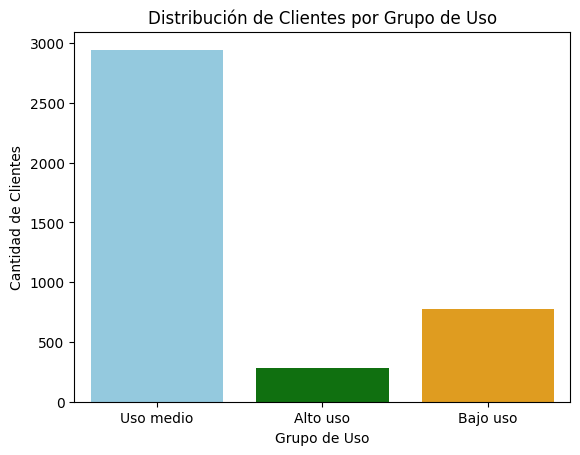

In [43]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', palette=['skyblue', 'green', 'orange'])
plt.title('Distribución de Clientes por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Clientes')
plt.show()

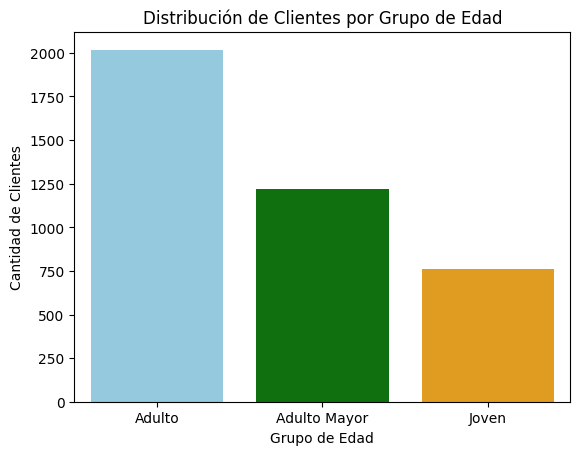

In [44]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', palette=['skyblue', 'green', 'orange'])
plt.title('Distribución de Clientes por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Clientes')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### ⚠️ Problemas detectados en los datos

- **`age`**: contenía el sentinel -999 en un subconjunto de registros, lo que distorsionaba la distribución (std de 123 vs. 17.7 después de la corrección). Fueron reemplazados por la mediana (48). Impacto: cualquier análisis demográfico previo a esta corrección habría sido inválido.
- **`city`**: 96 registros con sentinel "?" más 469 NaN reales (11.7% del total, 565 registros sin ciudad válida). Reemplazados con pd.NA y tratados como "unknown". Impacto moderado en análisis geográfico.
- **`reg_date`**: 40 registros con año 2026 (1% del total), imposibles al ser datos hasta 2024. Eliminados como errores de captura.
- **`date` en usage**: 50 registros sin fecha (0.12%), eliminados por no ser analizables temporalmente.
- **`duration` y `length`**: nulos estructurales por diseño (MAR). Los textos no tienen duración y las llamadas no tienen longitud. Conservados y analizados por separado según `type`.

---

### 👥 Segmentos por Edad

- El segmento **Adulto (30-59 años)** es el más grande con ~2000 clientes (50% de la base), seguido de **Adulto Mayor (60+)** con ~1250 clientes (31%) y **Joven (<30)** con ~750 clientes (19%).
- La distribución de edad es aproximadamente uniforme entre 20 y 80 años, sin concentración en ningún rango específico.
- La adopción del plan Premium se distribuye de manera similar en todos los grupos de edad, lo que indica que la decisión de plan no está fuertemente influenciada por la edad.

---

### 📊 Segmentos por Nivel de Uso

- **Uso medio** domina con ~2950 clientes (74% de la base): usuarios que realizan entre 5-9 llamadas y mensajes.
- **Bajo uso** representa ~780 clientes (19%): menos de 5 llamadas y 5 mensajes — clientes con bajo engagement que podrían estar en riesgo de churn.
- **Alto uso** es el segmento más pequeño con ~280 clientes (7%): más de 10 llamadas o mensajes — clientes de alto valor con consumo intensivo del servicio.
- Los usuarios Premium tienen mayor proporción en los rangos de uso alto, especialmente en llamadas (6-8) y mensajes (8-10).

---

### 💡 Esto sugiere que...

- El segmento de **Alto uso** (7% de clientes) probablemente genera una proporción desproporcionadamente alta de ingresos y es candidato prioritario para programas de retención y planes personalizados.
- El segmento de **Bajo uso** (19%) representa riesgo de churn — clientes que no están aprovechando el servicio y podrían cancelar. Se recomienda activación proactiva.
- Los **Adultos Mayores (60+)** son el segundo grupo más grande y tienen consumo estable — segmento valioso y potencialmente leal que merece campañas diferenciadas.

---

### 💼 Recomendaciones

- **Retención de Alto uso**: crear un plan "Power User" con minutos y mensajes ilimitados para los ~280 clientes de alto consumo, evitando que busquen alternativas en la competencia.
- **Activación de Bajo uso**: implementar campañas de re-engagement para los ~780 clientes de bajo uso — descuentos temporales, bonificación de minutos o mensajes gratuitos para estimular el consumo.
- **Segmentación por edad**: diseñar comunicaciones diferenciadas para Adultos Mayores (simplicidad, soporte) vs. Jóvenes (datos, mensajería, apps).
- **Revisión de calidad de datos**: estandarizar el proceso de captura de `city` y `age` para evitar sentinels como "?" y -999 en futuros registros — esto mejorará la calidad de análisis geográficos y demográficos.
- **Monitoreo de outliers de minutos**: los usuarios con más de 60 minutos de llamada (límite IQR) son candidatos a un plan de voz ilimitada — analizar su plan actual y ofrecer migración proactiva.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`